# 1. Ekstraksi dan agregasi data harga pangan surabaya (2023-2026) - R. Syailindra Alfarraiel - 24083010030

## Setup library

In [3]:
import os
import re
from datetime import date, timedelta
import pandas as pd
import numpy as np
import openpyxl

# Path direktori raw data (proyek BRIDA Simonpedia)
RAW_DATA_PATH = "/home/farel/Documents/SMT 5/BRIDA PROJECTS/simonpedia-bapok-surabaya/raw_data"

# Folder tahunan yang diproses
YEAR_FOLDERS = {
    2023: "2023-keseluruhan",
    2024: "2024-keseluruhan",
    2025: "2025-keseluruhan",
    2026: "2026-keseluruhan"
}

# Direktori Output Data dan Sub-folder Figures
DATA_DIR = "../data"
FIGURES_DIR = os.path.join(DATA_DIR, "figures")

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

CSV_OUTPUT_PATH = os.path.join(DATA_DIR, "seri_harian.csv")
EXCEL_OUTPUT_PATH = os.path.join(DATA_DIR, "seri_harian.xlsx")

print("Setup direktori selesai:")
print(f" - Data Folder   : {DATA_DIR}")
print(f" - Figures Folder: {FIGURES_DIR}")

Setup direktori selesai:
 - Data Folder   : ../data
 - Figures Folder: ../data/figures


## Membuat funggsi untuk ekstraksi

In [2]:
def extract_from_excel(file_path, year, month_num):
    """
    Mengekstrak harga harian untuk 3 komoditas dari sheet REKAPITULASI.
    Kolom 3 ke atas mewakili tanggal 1, 2, 3, dst.
    """
    records = []
    try:
        wb = openpyxl.load_workbook(file_path, data_only=True)
        # Ambil sheet REKAPITULASI
        sheet_name = 'REKAPITULASI' if 'REKAPITULASI' in wb.sheetnames else wb.sheetnames[0]
        ws = wb[sheet_name]
        
        target_rows = {}
        for row_idx, row in enumerate(ws.iter_rows(values_only=True)):
            if not row or len(row) < 2 or row[1] is None:
                continue
            name = str(row[1]).lower().strip()
            
            # Deteksi komoditas
            if 'rawit' in name and 'cabe_rawit' not in target_rows:
                target_rows['cabe_rawit'] = row
            elif 'bawang merah' in name and 'lokal' in name and 'bawang_merah' not in target_rows:
                target_rows['bawang_merah'] = row
            elif 'bawang merah' in name and 'bawang_merah' not in target_rows:
                target_rows['bawang_merah'] = row
            elif 'beras' in name and 'premium' in name and 'beras_premium' not in target_rows:
                target_rows['beras_premium'] = row
            elif 'beras ir.64 kwalitas i' in name and 'beras_premium' not in target_rows:
                target_rows['beras_premium'] = row

        # Ekstrak nilai harian (mulai kolom index 3)
        for day in range(1, 32):
            try:
                current_date = date(year, month_num, day)
            except ValueError:
                # Tanggal tidak valid untuk bulan terkait (misal 31 Feb)
                continue
            
            col_idx = 2 + day  # Index kolom excel untuk hari terkait
            
            row_data = {'tanggal': current_date.strftime('%Y-%m-%d')}
            valid_any = False
            
            for komoditas, row_vals in target_rows.items():
                if col_idx < len(row_vals):
                    val = row_vals[col_idx]
                    try:
                        # Bersihkan format angka string jika ada koma
                        val_num = float(str(val).replace(',', '').strip())
                        if val_num > 0:
                            row_data[komoditas] = val_num
                            valid_any = True
                        else:
                            row_data[komoditas] = np.nan
                    except (ValueError, TypeError):
                        row_data[komoditas] = np.nan
                else:
                    row_data[komoditas] = np.nan
            
            if valid_any:
                records.append(row_data)
                
    except Exception as e:
        print(f"Error pada file {os.path.basename(file_path)}: {e}")
        
    return records

## Eksekusi fungsi looping pada seluruh file

In [4]:
month_mapping = {
    '01': 1, 'JANUARI': 1,
    '02': 2, 'FEBRUARI': 2,
    '03': 3, 'MARET': 3,
    '04': 4, 'APRIL': 4,
    '05': 5, 'MEI': 5,
    '06': 6, 'JUNI': 6,
    '07': 7, 'JULI': 7,
    '08': 8, 'AGUSTUS': 8,
    '09': 9, 'SEPTEMBER': 9,
    '10': 10, 'OKTOBER': 10,
    '11': 11, 'NOVEMBER': 11,
    '12': 12, 'DESEMBER': 12
}

all_data = []

for year, folder_name in YEAR_FOLDERS.items():
    folder_dir = os.path.join(RAW_DATA_PATH, folder_name)
    if not os.path.exists(folder_dir):
        print(f"Direktori {folder_dir} tidak ditemukan, lewati.")
        continue
        
    file_list = sorted([f for f in os.listdir(folder_dir) if f.endswith('.xlsx') and not f.startswith('~$')])
    print(f"Memproses Tahun {year} ({len(file_list)} file)...")
    
    for fname in file_list:
        # Deteksi bulan dari nama file
        month_num = None
        fname_upper = fname.upper()
        for k, v in month_mapping.items():
            if fname.startswith(k + ".") or k in fname_upper:
                month_num = v
                break
        
        if month_num is None:
            continue
            
        file_path = os.path.join(folder_dir, fname)
        extracted = extract_from_excel(file_path, year, month_num)
        all_data.extend(extracted)

print(f"\nTotal data harian berhasil diekstrak: {len(all_data)} baris.")

Memproses Tahun 2023 (12 file)...
Memproses Tahun 2024 (12 file)...
Memproses Tahun 2025 (12 file)...
Memproses Tahun 2026 (8 file)...

Total data harian berhasil diekstrak: 1252 baris.


## Pembersihan grid tanggal, imputasi, dan interpolasi

In [5]:
df_raw = pd.DataFrame(all_data)

# Hapus duplikat tanggal jika ada (ambil data terakhir)
df_raw = df_raw.drop_duplicates(subset=['tanggal']).sort_values('tanggal').reset_index(drop=True)
df_raw['tanggal'] = pd.to_datetime(df_raw['tanggal'])

# Buat rentang tanggal harian lengkap (tanpa bolong)
full_date_range = pd.date_range(start=df_raw['tanggal'].min(), end=df_raw['tanggal'].max(), freq='D')
df = pd.DataFrame({'tanggal': full_date_range})

# Merge dengan data asli
df = df.merge(df_raw, on='tanggal', how='left')
df.set_index('tanggal', inplace=True)

print("Ringkasan Missing Values sebelum interpolasi:")
print(df.isna().sum())

# Interpolasi linear untuk jeda hari libur, lalu bfill/ffill jika ada tepi kosong
df = df.interpolate(method='time').bfill().ffill()

print("\nMissing Values setelah interpolasi (Harus 0):")
print(df.isna().sum())
print(f"Total baris kontinu: {len(df)} hari.")

Ringkasan Missing Values sebelum interpolasi:
beras_premium    919
cabe_rawit       920
bawang_merah     920
dtype: int64

Missing Values setelah interpolasi (Harus 0):
beras_premium    0
cabe_rawit       0
bawang_merah     0
dtype: int64
Total baris kontinu: 1155 hari.


In [6]:
# Tampilkan preview data
print("--- 5 Data Awal ---")
print(df.head())
print("\n--- 5 Data Akhir ---")
print(df.tail())

# 1. Simpan ke CSV
df.to_csv(CSV_OUTPUT_PATH, index=True)
print(f"\n[SUKSES] File CSV tersimpan di  : {CSV_OUTPUT_PATH}")

# 2. Simpan ke Excel (.xlsx)
df.to_excel(EXCEL_OUTPUT_PATH, index=True)
print(f"[SUKSES] File Excel tersimpan di: {EXCEL_OUTPUT_PATH}")

--- 5 Data Awal ---
            beras_premium   cabe_rawit  bawang_merah
tanggal                                             
2023-01-01    12471.42857  47857.14286   31857.14286
2023-01-02    12471.42857  61428.57143   32571.42857
2023-01-03    12471.42857  64285.71429   32571.42857
2023-01-04    12471.42857  65000.00000   32714.28571
2023-01-05    12471.42857  57857.14286   32571.42857

--- 5 Data Akhir ---
            beras_premium   cabe_rawit  bawang_merah
tanggal                                             
2026-02-24    15814.28571  75000.00000   36714.28571
2026-02-25    15814.28571  78571.42857   36285.71429
2026-02-26    15814.28571  80000.00000   36285.71429
2026-02-27    15814.28571  77142.85714   35857.14286
2026-02-28    15814.28571  78160.71429   36489.79592

[SUKSES] File CSV tersimpan di  : ../data/seri_harian.csv
[SUKSES] File Excel tersimpan di: ../data/seri_harian.xlsx


## Simpan Data

Grafik tersimpan di: ../data/figures/overview_seri_harian.png


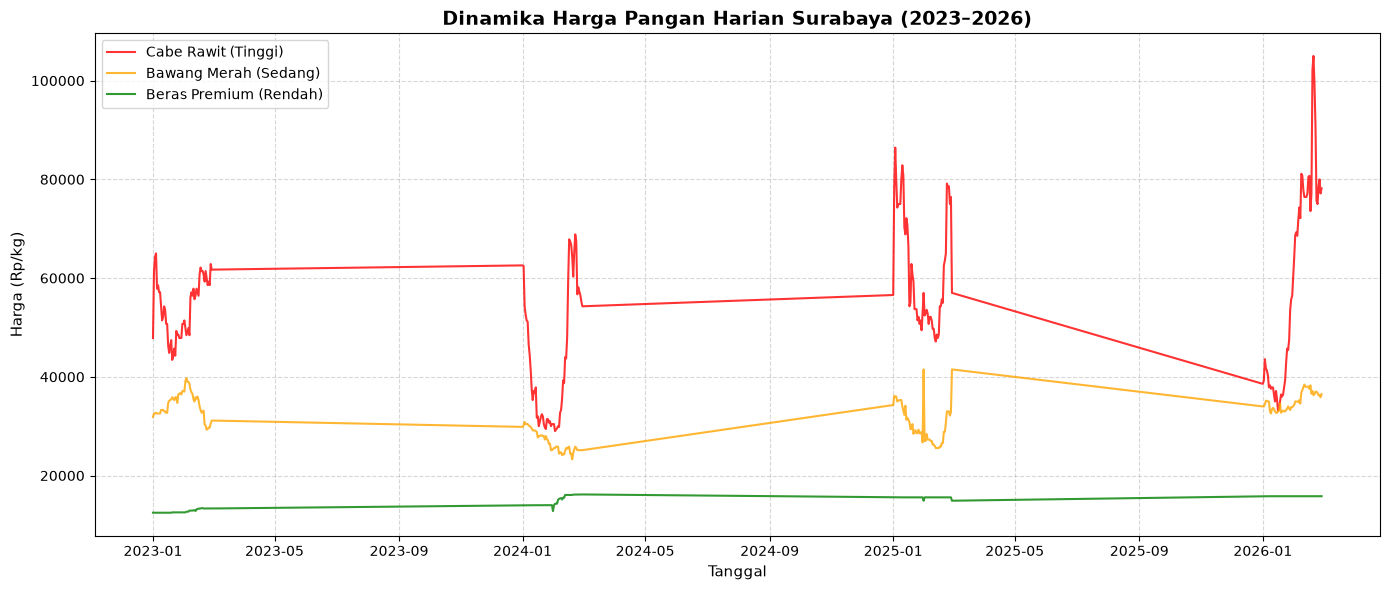

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plt.plot(df.index, df['cabe_rawit'], label='Cabe Rawit (Tinggi)', color='red', alpha=0.8)
plt.plot(df.index, df['bawang_merah'], label='Bawang Merah (Sedang)', color='orange', alpha=0.8)
plt.plot(df.index, df['beras_premium'], label='Beras Premium (Rendah)', color='green', alpha=0.8)

plt.title('Dinamika Harga Pangan Harian Surabaya (2023–2026)', fontsize=14, fontweight='bold')
plt.xlabel('Tanggal', fontsize=11)
plt.ylabel('Harga (Rp/kg)', fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Simpan gambar ke sub-folder data/figures/
fig_path = os.path.join(FIGURES_DIR, "overview_seri_harian.png")
plt.savefig(fig_path, dpi=300)
print(f"Grafik tersimpan di: {fig_path}")

# Tampilkan di notebook
plt.show()